# Charge transport in amorphous thiophene

How mobile are electrons and holes in an amorphous film of thiophene? This tutorial goes through the multiscale workflow that answers this question: from the MD morphology to the parameters of the hopping rates, and from the rates to mobilities and times of flight.

Charges hop between molecules $i$ and $j$ with the Marcus rate

$$\omega_{ij} = \frac{2\pi}{\hbar}\frac{|J_{ij}|^2}{\sqrt{4\pi\lambda_{ij}k_\mathrm{B}T}}\exp\left[-\frac{(\Delta E_{ij} - q\mathbf{F}\cdot\mathbf{r}_{ij} - \lambda_{ij})^2}{4\lambda_{ij}k_\mathrm{B}T}\right],$$

which needs three ingredients for every pair of neighbours:

1. the **reorganization energy** $\lambda$ (from gas-phase calculations of a single molecule),
2. the **site energy difference** $\Delta E_{ij} = E_i - E_j$ (internal energies plus the electrostatic and polarization energy of the charge in its environment),
3. the **electronic coupling** $J_{ij}$ (from DFT calculations of the pair).

Computing these for all 1000 molecules and 10151 pairs takes hours, so here we compute them for a few molecules and pairs, compare with the full set provided in `state_reference.hdf5`, and then use the full set for the transport calculations.

The morphology and the mapping are explained in the tutorial *From an MD morphology to a state file*.

## Requirements
* VOTCA installed and the environment activated with `VOTCARC.bash` (see the [installation instructions](https://github.com/votca/votca/blob/master/share/sphinx/INSTALL.rst)).
* Python with `numpy`, `h5py` and `matplotlib`.

In [1]:
import subprocess
import numpy as np
import h5py
import matplotlib.pyplot as plt


def run(command, show=0, output=False):
    """Run a VOTCA command; print the last `show` lines of its output (0: none)."""
    result = subprocess.run(command, shell=True, text=True,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if result.returncode != 0:
        print(result.stdout)
        raise RuntimeError(f"'{command}' failed")
    if show:
        print("\n".join(result.stdout.splitlines()[-show:]))
    return result.stdout if output else None
import xml.etree.ElementTree as ET

HARTREE = 27.211386  # eV
BOHR = 0.0529177  # nm


def only_jobs(jobfile, ids):
    """Mark all jobs except those with the given ids as COMPLETE, so only these run."""
    tree = ET.parse(jobfile)
    for job in tree.getroot().iter("job"):
        if int(job.find("id").text) not in ids:
            job.find("status").text = "COMPLETE"
    tree.write(jobfile)


def results(filename):
    """Read a 'key value unit' result file of the transport calculators into a dictionary."""
    values = {}
    for line in open(filename):
        if line.startswith("#") or not line.strip():
            continue
        key, value = line.split()[:2]
        try:
            values[key] = float(value)
        except ValueError:
            values[key] = value
    return values

run("rm -rf state.hdf5 *.jobs *_jobs.xml ewaldbackground.hdf5 OR_FILES QMMM qmmm_mm.xml eqm.xml iqm.xml")

## Morphology and neighbours

We map the MD snapshot and list the pairs whose closest atoms are less than 0.6 nm apart:

In [2]:
run("xtp_map -t MD_FILES/thiophene.data -c MD_FILES/traj.dump -s system.xml -f state.hdf5")
run("xtp_run -e neighborlist -c constant=0.6 -f state.hdf5", show=0)

## Reorganization and internal energies

The internal energies of the charged molecule come from four gas-phase calculations (neutral and charged molecule, each at its own optimized geometry and at that of the other state) and are listed in the mapping file `system.xml` (in eV):

* `U_xX_nN`: energy of the charged molecule in its geometry minus that of the neutral molecule in its geometry (electron affinity or ionization energy, up to the sign),
* `U_nX_nN`: energy of the neutral molecule in the geometry of the charged one, relative to its minimum,
* `U_xN_xX`: energy of the charged molecule in the neutral geometry, relative to its minimum.

The reorganization energy of a hop is $\lambda = $ `U_nX_nN` $+$ `U_xN_xX`. `einternal` copies these values into the state file:

In [3]:
run("xtp_run -e einternal -c energies_file=system.xml -f state.hdf5")
segment = ET.parse("system.xml").getroot().find(".//segment")
for carrier, name in [("e", "electron"), ("h", "hole")]:
    lam = float(segment.find(f"U_nX_nN_{carrier}").text) + float(segment.find(f"U_xN_xX_{carrier}").text)
    print(f"{name}: reorganization energy {lam:.3f} eV")

electron: reorganization energy 0.382 eV
hole: reorganization energy 0.762 eV


## Site energies in the environment

A charge on a molecule interacts with the permanent multipoles of the surrounding molecules and polarizes them. This changes the site energy by several tenths of an eV and, since every molecule has a different environment, causes the energetic disorder that dominates transport in amorphous materials.

We describe the environment classically: every molecule carries the atomic multipoles and polarizabilities of `MP_FILES` (for its state `n`, `e` or `h`), and induced dipoles are computed self-consistently. Electrostatics are long-ranged, so the periodic environment is included with Ewald summation in two steps:

1. `ewaldbackground` converges the induced dipoles of the whole periodic neutral system once.
2. For each molecule and state, a `qmmm` job places the molecule in the given state into an explicitly polarizable shell (here 1.5 nm) inside the frozen periodic background. The site energy is the energy difference between the charged and the neutral job.

The settings below trade accuracy for speed (`screening_factor=4` instead of 6 and a looser tolerance); with the defaults `ewaldbackground` takes several minutes here.

In [4]:
run("xtp_run -e ewaldbackground -c multipoles=system.xml realspace.screening_factor=4.0 "
    "polarmethod.tolerance=1e-5 polarmethod.use_block_jacobi_preconditioner=true -f state.hdf5", show=0)

The options of the `qmmm` jobs are given in an XML file. Region 0 is the explicitly polarizable shell around the molecule of the job, region 1 the periodic background:

In [5]:
qmmm_options = """<?xml version="1.0"?>
<options>
  <qmmm>
    <map_file>system.xml</map_file>
    <job_file>qmmm_mm_jobs.xml</job_file>
    <io_jobfile>
      <states>n e h</states>
      <segments>0 1 2</segments>
    </io_jobfile>
    <regions>
      <polarregion>
        <id>0</id>
        <segments>jobfile</segments>
        <cutoff>
          <geometry>n</geometry>
          <radius>1.5</radius>
          <region>0</region>
        </cutoff>
      </polarregion>
      <ewaldregion>
        <id>1</id>
        <checkpoint>ewaldbackground.hdf5</checkpoint>
      </ewaldregion>
    </regions>
  </qmmm>
</options>
"""
with open("qmmm_mm.xml", "w") as f:
    f.write(qmmm_options)

Jobs are handled by `xtp_parallel` in three steps: `-j write` writes a job file with one job per molecule and state (here molecules 0, 1 and 2 in the states `n`, `e`, `h`), `-j run` runs the jobs (several processes can work on the same job file, `-x` sets the threads per job), and `-j read` stores the results in the state file:

In [6]:
run("xtp_parallel -e qmmm -o qmmm_mm.xml -f state.hdf5 -j write")
run("xtp_parallel -e qmmm -o qmmm_mm.xml -f state.hdf5 -j run -x 2")
run("xtp_parallel -e qmmm -o qmmm_mm.xml -f state.hdf5 -j read")

with h5py.File("state.hdf5", "r") as mine, h5py.File("state_reference.hdf5", "r") as ref:
    ours = mine["frame_10000"]["segments"]
    theirs = ref["frame_10000"]["segments"]
    print("molecule  carrier  this run (eV)  reference (eV)")
    for i in range(3):
        for carrier in "eh":
            a = ours[f"segment{i}"].attrs[f"site_eng_{carrier}"].item() * HARTREE
            b = theirs[f"segment{i}"].attrs[f"site_eng_{carrier}"].item() * HARTREE
            print(f"{i:8d}  {carrier:>7}  {a:13.3f}  {b:14.3f}")

molecule  carrier  this run (eV)  reference (eV)
       0        e         -0.669          -0.702
       0        h         -0.860          -0.828
       1        e         -0.538          -0.565
       1        h         -0.953          -0.925
       2        e         -0.660          -0.681
       2        h         -0.906          -0.885


The environment lowers the energy of both carriers by 0.5 to 1 eV, by different amounts for different molecules. The reference set was computed for all molecules with comparable settings; the values agree to within a few hundredths of an eV, the size of the differences caused by the settings.

## Electronic couplings

The coupling $J_{ij}$ of a pair is computed by projecting the frontier orbitals of the two molecules onto the orbitals of the pair (dimer projection, `dftcoupling`). This needs a DFT calculation of each molecule (`eqm`) and of each pair (`iqm`). We compute the first three pairs of the neighbour list, which share molecule 0:

In [7]:
with h5py.File("state.hdf5", "r") as f:
    pairs = f["frame_10000"]["neighborlist"]["pairs"][()].ravel()
chosen = [0, 1, 2]
molecules = sorted({int(m) for p in chosen for m in (pairs[p]["Seg1Id"], pairs[p]["Seg2Id"])})
print("pairs:", [(int(pairs[p]["Seg1Id"]), int(pairs[p]["Seg2Id"])) for p in chosen])

dft = """
    <dftpackage>
      <basisset>3-21G</basisset>
      <auxbasisset>aux-def2-svp</auxbasisset>
    </dftpackage>"""
open("eqm.xml", "w").write(f"""<?xml version="1.0"?>
<options><eqm><map_file>system.xml</map_file><tasks>input,dft,parse</tasks>{dft}
</eqm></options>""")
open("iqm.xml", "w").write(f"""<?xml version="1.0"?>
<options><iqm><map_file>system.xml</map_file><tasks>input,dft,parse,dftcoupling</tasks>{dft}
    <readjobfile><electron>thiophene:e1</electron><hole>thiophene:h1</hole></readjobfile>
</iqm></options>""")

run("xtp_parallel -e eqm -o eqm.xml -f state.hdf5 -j write")
only_jobs("eqm.jobs", molecules)
run("xtp_parallel -e eqm -o eqm.xml -f state.hdf5 -j run -x 2")

run("xtp_parallel -e iqm -o iqm.xml -f state.hdf5 -j write")
only_jobs("iqm.jobs", chosen)
run("xtp_parallel -e iqm -o iqm.xml -f state.hdf5 -j run -x 2")
run("xtp_parallel -e iqm -o iqm.xml -f state.hdf5 -j read")

pairs: [(0, 9), (0, 19), (0, 88)]


`readjobfile` selects which orbitals are stored as the coupling of each carrier: the LUMO (`e1`) for electrons and the HOMO (`h1`) for holes. The state file stores $|J|^2$ (in Hartree$^2$):

In [8]:
with h5py.File("state.hdf5", "r") as mine, h5py.File("state_reference.hdf5", "r") as ref:
    a = mine["frame_10000"]["neighborlist"]["pairs"][()].ravel()
    b = ref["frame_10000"]["neighborlist"]["pairs"][()].ravel()
print("pair      carrier  |J| this run (meV)  |J| reference (meV)")
for p in chosen:
    for carrier in "eh":
        j_a = np.sqrt(a[p][f"jeff2{carrier}"]) * HARTREE * 1000
        j_b = np.sqrt(b[p][f"jeff2{carrier}"]) * HARTREE * 1000
        print(f"{int(a[p]['Seg1Id']):3d}-{int(a[p]['Seg2Id']):<4d}  {carrier:>7}  {j_a:18.3g}  {j_b:19.3g}")

pair      carrier  |J| this run (meV)  |J| reference (meV)
  0-9           e                70.2                 67.2
  0-9           h                44.3                 46.4
  0-19          e                2.57                 6.79
  0-19          h                 2.3                 5.91
  0-88          e             0.00121                    0
  0-88          h             0.00349                    0


The couplings decrease exponentially with the distance and depend strongly on the relative orientation of the molecules: the three pairs of molecule 0 span several orders of magnitude. The strong coupling agrees closely with the reference; the weak ones differ by up to a factor of a few, since small couplings are sensitive to the tails of the orbitals and hence to the basis set (here the small 3-21G). The pair 0-88 is 0.9 nm apart and its coupling is negligible; in the reference set, such distant pairs (about a third of the neighbour list) have no coupling at all ($J=0$), which makes no difference for transport.

## Transport

The reference state file contains all ingredients for all molecules and pairs. Its distributions of site energies and couplings give a first impression of the transport properties: `eanalyze` and `ianalyze` write histograms.

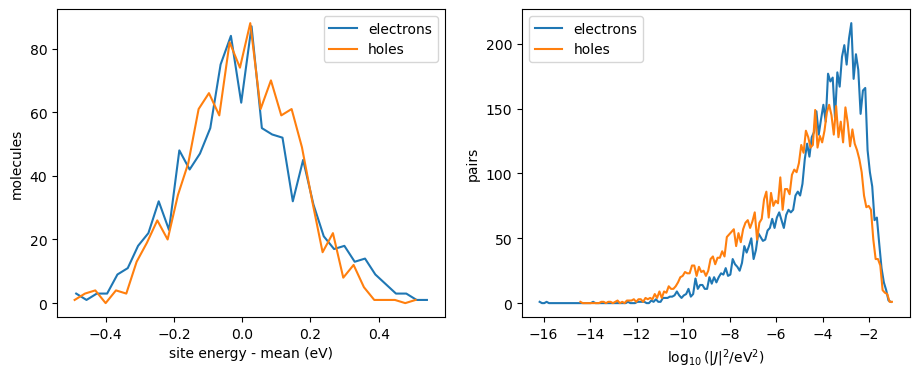

In [9]:
run("xtp_run -e eanalyze -c resolution_sites=0.03 -f state_reference.hdf5")
run("xtp_run -e ianalyze -c resolution_logJ2=0.1 states=e,h -f state_reference.hdf5")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for carrier, label in [("e", "electrons"), ("h", "holes")]:
    hist = np.loadtxt(f"eanalyze.sitehist_{carrier}.out")
    ax1.plot(hist[:, 0] - np.average(hist[:, 0], weights=hist[:, 1]), hist[:, 1], label=label)
    coupling = np.loadtxt(f"ianalyze.ihist_{carrier}.out")
    ax2.plot(coupling[:, 0], coupling[:, 1], label=label)
ax1.set_xlabel("site energy - mean (eV)")
ax1.set_ylabel("molecules")
ax1.legend()
ax2.set_xlabel(r"$\log_{10}(|J|^2/\mathrm{eV}^2)$")
ax2.set_ylabel("pairs")
ax2.legend()
plt.show()

The width of the site energy distribution, the energetic disorder $\sigma$, controls how strongly carriers are trapped; the couplings span many orders of magnitude, so a few well-coupled pairs carry most of the current.

### Bulk mobility

`kmcmultiple` follows carriers through the periodic box with kinetic Monte Carlo (KMC) and also solves the master equation for a single carrier exactly (`exact_mobility`), which needs no sampling:

In [10]:
run('xtp_run -e kmcmultiple -c carriertype=electron field="1e7 0 0" numberofcarriers=1 runs=8 '
    'runtime=10000000 outputtime=0 -f state_reference.hdf5')
r = results("kmcmultiple_results.dat")
print(f"KMC {r['mobility']:.2e} +- {r['mobility_error']:.1e} cm^2/Vs, exact {r['exact_mobility']:.2e} cm^2/Vs")

KMC 7.99e-06 +- 6.5e-07 cm^2/Vs, exact 8.40e-06 cm^2/Vs


The statistical error of the KMC is large: the electron spends most of its time on a few low-energy molecules and leaves them rarely. The exact value is cheap, so we use it (with a minimal KMC part, `runtime=1000`) to compare electrons and holes over a range of fields:

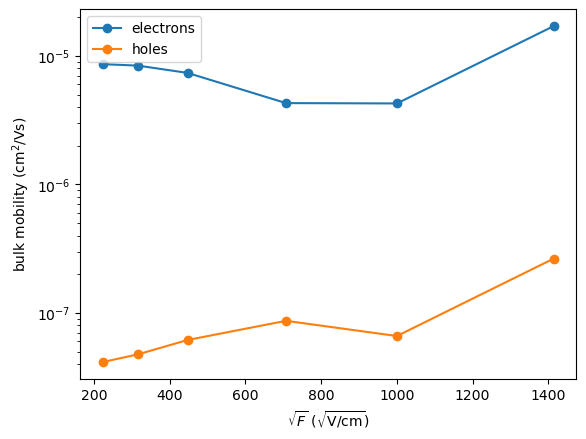

In [11]:
fields = np.array([0.5, 1, 2, 5, 10, 20]) * 1e7  # V/m
for carrier in ["electron", "hole"]:
    mu = []
    for F in fields:
        run(f'xtp_run -e kmcmultiple -c carriertype={carrier} field="{F} 0 0" runtime=1000 outputtime=0 '
            'resultfile=scan.dat ratefile=x occfile=x -f state_reference.hdf5')
        mu.append(results("scan.dat")["exact_mobility"])
    plt.semilogy(np.sqrt(fields / 1e2), mu, "o-", label=carrier + "s")
plt.xlabel(r"$\sqrt{F}$ ($\sqrt{\mathrm{V/cm}}$)")
plt.ylabel("bulk mobility (cm$^2$/Vs)")
plt.legend()
plt.show()

Electrons are about two orders of magnitude more mobile than holes in this morphology, largely because the reorganization energy of the hole is twice as large. The irregular field dependence reflects the few low-energy molecules that dominate transport in such a small box.

### Time of flight and traps

In a time-of-flight experiment, carriers are injected at one electrode and the time until they reach the other is measured. `grw` computes the mean time of flight exactly for a slab cut from the box along $x$ (electrons are injected in a 1 nm layer at one face and collected at the other; they move against the field, so the field points in $-x$). It also writes, in `grw_occupation.dat`, the fraction of the time of flight that the electron spends on each molecule:

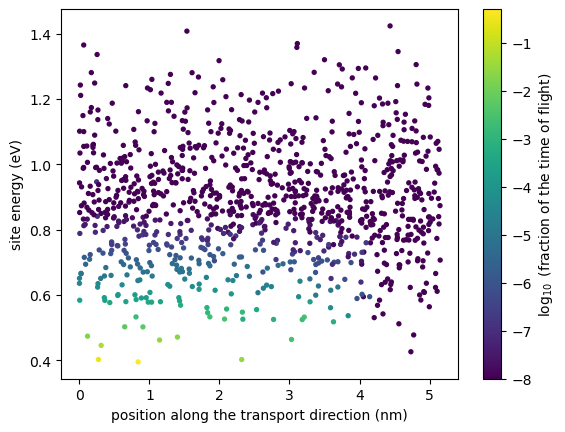

time of flight 3.93e-07 s
molecule 19: x = 0.84 nm, energy 0.395 eV, 50% of the time of flight
molecule 909: x = 0.27 nm, energy 0.403 eV, 30% of the time of flight
molecule 995: x = 0.31 nm, energy 0.446 eV, 6% of the time of flight
molecule 353: x = 2.32 nm, energy 0.402 eV, 3% of the time of flight
molecule 70: x = 1.14 nm, energy 0.462 eV, 3% of the time of flight


In [12]:
run('xtp_run -e grw -c carriertype=electron field="-1e7 0 0" -f state_reference.hdf5')
grw = results("grw_results.dat")
occ = np.loadtxt("grw_occupation.dat", usecols=(0, 1, 2, 5))
segment, x, energy, fraction = occ.T
plt.scatter(x, energy, c=np.log10(np.maximum(fraction, 1e-8)), s=8, cmap="viridis")
plt.colorbar(label=r"$\log_{10}$ (fraction of the time of flight)")
plt.xlabel("position along the transport direction (nm)")
plt.ylabel("site energy (eV)")
plt.show()
print(f"time of flight {grw['tau_mean']:.2e} s")
for s in np.argsort(fraction)[::-1][:5]:
    print(f"molecule {int(segment[s])}: x = {x[s]:.2f} nm, energy {energy[s]:.3f} eV, "
          f"{fraction[s]:.0%} of the time of flight")

A handful of molecules hold the electron for most of the time of flight. `kmctof` simulates the same experiment with KMC; its mean transit time agrees with `grw` within the statistical error, and the distribution over runs shows how broad the transit times are:

KMC 3.59e-07 +- 2.1e-08 s, grw 3.93e-07 s


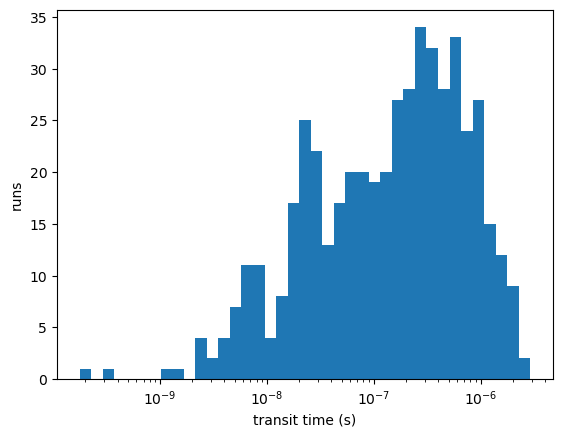

In [13]:
run('xtp_run -e kmctof -c carriertype=electron field="-1e7 0 0" runs=500 -f state_reference.hdf5')
tof = results("kmctof_results.dat")
print(f"KMC {tof['transit_mean']:.2e} +- {tof['transit_error']:.1e} s, grw {grw['tau_mean']:.2e} s")
transit = np.loadtxt("kmctof_runs.dat", usecols=5)
plt.hist(transit, bins=np.logspace(np.log10(transit.min()), np.log10(transit.max()), 40))
plt.xscale("log")
plt.xlabel("transit time (s)")
plt.ylabel("runs")
plt.show()

## Summary

* Hopping rates need reorganization energies (`einternal`), site energies in the environment (`ewaldbackground` and `qmmm`) and couplings (`eqm` and `iqm`); `xtp_parallel` distributes the per-molecule and per-pair jobs.
* `kmcmultiple` gives bulk mobilities, its exact single-carrier value without statistical error; `grw` and `kmctof` give times of flight, and the occupation map of `grw` identifies the molecules that act as traps.
* This morphology is small (1000 molecules, about 5 nm): its mobilities are dominated by a few sites and should be taken as an illustration. Production calculations need larger systems (see the stochastic network model in the manual chapter *Transport Simulations*) and several snapshots.